# Same state, two markets: S&P 500 options vs Kalshi event contracts

**Objective:** part of my Graduating Project. A Kalshi contract "S&P 500 at or above K at the close" pays 1 dollar in one state of the world: it is an Arrow-Debreu claim, a digital option. Listed options price the same claim, only implicitly: the slope of the call price across strikes is the risk-neutral probability of finishing above each strike (Breeden and Litzenberger, 1978).

Here we take **the same expiry** in both markets (S&P 500 close of 23 October 2026, 4 pm New York), and compare:
1. the risk-neutral distribution from the options (with an SVI smile fitted to the implied volatilities)
2. the distribution quoted directly by the ladder of Kalshi contracts

and we measure the distance between the two distributions, the variable I propose for the panel of the thesis. We repeat it with the Nasdaq-100.

**Data:** SPXW and NDX options (Cboe, via Yahoo Finance) and Kalshi public API (series KXINXU and KXNASDAQ100U). It is a snapshot: the notebook saves the quotes in `data/` the first time it runs.

Libraries of the project: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `requests` and `yfinance`.

## Part 1. Libraries

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import yfinance as yf
from scipy.stats import norm
from scipy.optimize import brentq, least_squares

import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)
K_API = "https://api.elections.kalshi.com/trade-api/v2"
VENCIMIENTO = "2026-10-23"
CIERRE = pd.Timestamp("2026-10-23 16:00", tz="America/New_York")

## Part 2. Snapshot of the two markets

For the options we keep bid, ask and open interest of every strike. For Kalshi, the event of the 4 pm close has one market per strike: "at or above K". We save the time of the snapshot, because both markets have to be observed at the same moment.

In [2]:
def foto(indice, serie, evento):
    ruta = f"data/snapshot_{serie}.csv"
    if os.path.exists(ruta):
        return pd.read_csv(ruta)
    t = yf.Ticker(indice)
    ch = t.option_chain(VENCIMIENTO)
    spot = t.history(period="1d")["Close"].iloc[-1]
    filas = []
    for tipo, d in [("call", ch.calls), ("put", ch.puts)]:
        for _, r in d.iterrows():
            filas.append({"market": "options", "type": tipo, "strike": r["strike"], "bid": r["bid"], "ask": r["ask"],
                          "open_interest": r.get("openInterest"), "spot": spot})
    ev = requests.get(f"{K_API}/events/{evento}", timeout=60).json()
    for m in ev["markets"]:
        filas.append({"market": "kalshi", "type": "above", "strike": m["floor_strike"],
                      "bid": float(m.get("yes_bid_dollars") or 0), "ask": float(m.get("yes_ask_dollars") or 0),
                      "open_interest": float(m.get("open_interest_fp") or 0), "spot": spot})
    d = pd.DataFrame(filas)
    d["snapshot_utc"] = pd.Timestamp.now(tz="UTC").isoformat()
    d.to_csv(ruta, index=False)
    return d

spx = foto("^SPX", "spx", "KXINXU-26OCT23H1600")
ndx = foto("^NDX", "ndx", "KXNASDAQ100U-26OCT23H1600")
print("Snapshot:", spx["snapshot_utc"].iloc[0])
print("S&P 500 | options:", (spx["market"] == "options").sum(), "| Kalshi strikes:", (spx["market"] == "kalshi").sum(), "| spot:", round(spx["spot"].iloc[0], 2))
print("Nasdaq-100 | options:", (ndx["market"] == "options").sum(), "| Kalshi strikes:", (ndx["market"] == "kalshi").sum(), "| spot:", round(ndx["spot"].iloc[0], 2))

Snapshot: 2026-10-22T20:25:40.549614+00:00
S&P 500 | options: 480 | Kalshi strikes: 60 | spot: 7663.43
Nasdaq-100 | options: 294 | Kalshi strikes: 400 | spot: 28958.69


## Part 3. From option prices to the risk-neutral distribution

Steps:
1. Time to expiry in years and forward price from put-call parity (C - P = DF x (F - K)) at the strikes near the money.
2. Implied volatility of each out-of-the-money option (mid price).
3. Fit an **SVI** smile to the total implied variance w(k) = sigma^2 T, with k = ln(K/F) (Gatheral): w(k) = a + b [rho (k - m) + sqrt((k - m)^2 + s^2)]. The SVI gives a smooth smile, which is necessary before differentiating.
4. P(S_T >= K) = - dC/dK (in forward terms), calculated with finite differences on the SVI prices.

In [3]:
def bs_call(F, K, T, sig):
    d1 = (np.log(F / K) + 0.5 * sig ** 2 * T) / (sig * np.sqrt(T))
    return F * norm.cdf(d1) - K * norm.cdf(d1 - sig * np.sqrt(T))

def bs_put(F, K, T, sig):
    return bs_call(F, K, T, sig) - (F - K)

def densidad_opciones(d, nombre):
    T = (CIERRE - pd.Timestamp(d["snapshot_utc"].iloc[0])).total_seconds() / (365 * 86400)
    op = d[d["market"] == "options"].copy()
    op["mid"] = (op["bid"] + op["ask"]) / 2
    op = op[(op["bid"] > 0) & (op["ask"] > 0)]
    piv = op.pivot_table(index="strike", columns="type", values="mid").dropna()
    spot = d["spot"].iloc[0]
    cerca = piv.iloc[np.argsort(np.abs(piv.index.values - spot))[:8]]
    F = np.median(cerca.index.values + cerca["call"].values - cerca["put"].values)    # one day: discounting is negligible
    otm = op[((op["type"] == "call") & (op["strike"] >= F)) | ((op["type"] == "put") & (op["strike"] < F))].copy()
    def iv(r):
        f = bs_call if r["type"] == "call" else bs_put
        try:
            return brentq(lambda s: f(F, r["strike"], T, s) - r["mid"], 1e-4, 5)
        except ValueError:
            return np.nan
    otm["iv"] = otm.apply(iv, axis=1)
    otm = otm.dropna(subset=["iv"])
    otm["k"] = np.log(otm["strike"] / F)
    otm = otm[otm["k"].abs() < 0.06]
    w = otm["iv"] ** 2 * T

    def svi(p, k):
        a, b, rho, m, s = p
        return a + b * (rho * (k - m) + np.sqrt((k - m) ** 2 + s ** 2))
    res = least_squares(lambda p: svi(p, otm["k"].values) - w.values, x0=[w.min(), 0.1 * T, -0.5, 0.0, 0.01],
                        bounds=([-1, 0, -0.999, -0.2, 1e-5], [1, 5, 0.999, 0.2, 1]))
    print(nombre, "| T (days):", round(T * 365, 2), "| forward:", round(F, 2), "| options used:", len(otm),
          "| SVI error (vol points):", round(np.sqrt(np.mean((np.sqrt(svi(res.x, otm["k"].values) / T) - otm["iv"]) ** 2)) * 100, 2))
    return F, T, otm, res.x, svi

def prob_arriba(K, F, T, params, svi):
    h = F * 0.0005
    def c(x):
        sig = np.sqrt(svi(params, np.log(x / F)) / T)
        return bs_call(F, x, T, sig)
    return -(c(K + h) - c(K - h)) / (2 * h)

F_spx, T_spx, otm_spx, p_spx, svi = densidad_opciones(spx, "S&P 500")
F_ndx, T_ndx, otm_ndx, p_ndx, _ = densidad_opciones(ndx, "Nasdaq-100")

S&P 500 | T (days): 0.98 | forward: 7666.52 | options used: 129 | SVI error (vol points): 0.56
Nasdaq-100 | T (days): 0.98 | forward: 28966.08 | options used: 81 | SVI error (vol points): 1.13


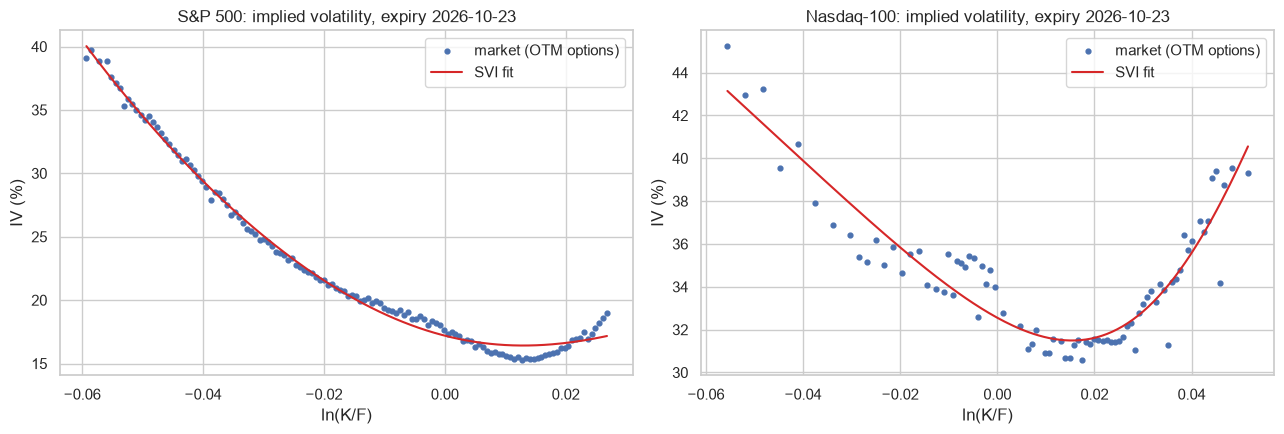

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (otm, p, F, T, nombre) in zip(axes, [(otm_spx, p_spx, F_spx, T_spx, "S&P 500"), (otm_ndx, p_ndx, F_ndx, T_ndx, "Nasdaq-100")]):
    k = np.linspace(otm["k"].min(), otm["k"].max(), 200)
    ax.scatter(otm["k"], otm["iv"] * 100, s=12, label="market (OTM options)")
    ax.plot(k, np.sqrt(svi(p, k) / T) * 100, color="tab:red", label="SVI fit")
    ax.set_title(f"{nombre}: implied volatility, expiry {VENCIMIENTO}")
    ax.set_xlabel("ln(K/F)")
    ax.set_ylabel("IV (%)")
    ax.legend()
plt.tight_layout()
plt.savefig("figures/svi_smiles.png", bbox_inches="tight")
plt.show()

## Part 4. The Kalshi ladder

Each Kalshi market gives the probability of finishing at or above its strike directly (mid between bid and ask). We also keep the half spread, because it is the uncertainty of that price.

In [5]:
def escalera(d, F, T, p):
    k = d[d["market"] == "kalshi"].copy()
    k = k[(k["ask"] > 0) & (k["bid"] < 1)]
    k["kalshi_mid"] = (k["bid"] + k["ask"]) / 2
    k["half_spread"] = (k["ask"] - k["bid"]) / 2
    k["options_prob"] = [prob_arriba(x, F, T, p, svi) for x in k["strike"]]
    k["wedge"] = k["kalshi_mid"] - k["options_prob"]
    k["k"] = np.log(k["strike"] / F)
    # implied volatility of the Kalshi price: the sigma that gives the same digital price N(d2)
    def iv_digital(r):
        if not 0.01 < r["kalshi_mid"] < 0.99:
            return np.nan
        f = lambda s: norm.cdf((np.log(F / r["strike"]) - 0.5 * s ** 2 * T) / (s * np.sqrt(T))) - r["kalshi_mid"]
        try:
            return brentq(f, 0.01, 3)
        except ValueError:
            return np.nan
    k["kalshi_implied_vol"] = k.apply(iv_digital, axis=1)
    return k.sort_values("strike")

esc_spx = escalera(spx, F_spx, T_spx, p_spx)
esc_ndx = escalera(ndx, F_ndx, T_ndx, p_ndx)
esc_spx[["strike", "bid", "ask", "kalshi_mid", "options_prob", "wedge", "half_spread"]].round(3).iloc[::3]

,strike,bid,ask,kalshi_mid,options_prob,wedge,half_spread
480,7600.0,0.81,0.86,0.835,0.844,-0.009,0.025
483,7615.0,0.77,0.82,0.795,0.791,0.004,0.025
486,7630.0,0.71,0.76,0.735,0.726,0.009,0.025
489,7645.0,0.65,0.70,0.675,0.649,0.026,0.025
492,7660.0,0.57,0.61,0.590,0.563,0.027,0.020
495,7675.0,0.49,0.52,0.505,0.471,0.034,0.015
498,7690.0,0.40,0.42,0.410,0.380,0.030,0.010
501,7705.0,0.30,0.32,0.310,0.293,0.017,0.010
504,7720.0,0.22,0.26,0.240,0.217,0.023,0.020
507,7735.0,0.15,0.19,0.170,0.153,0.017,0.020


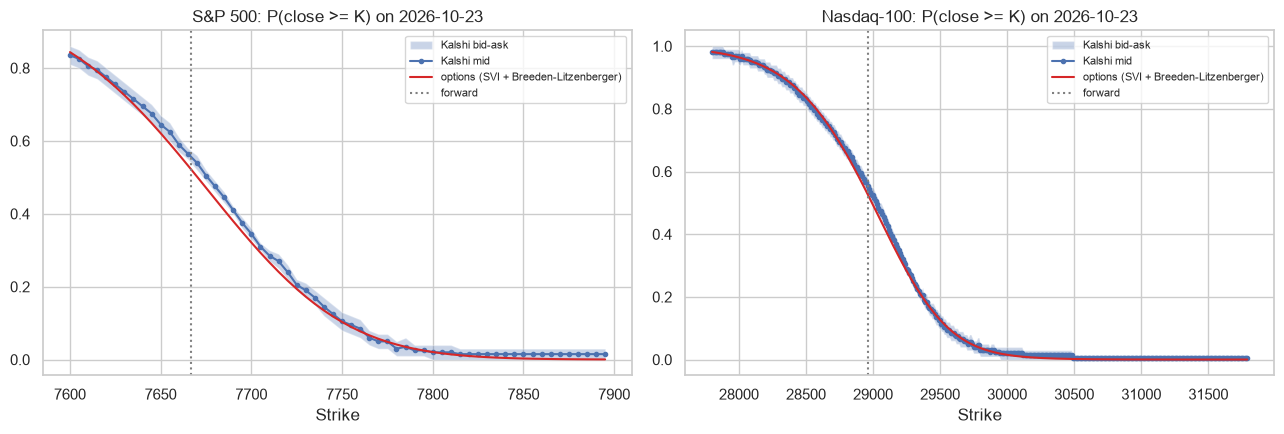

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (e, F, nombre) in zip(axes, [(esc_spx, F_spx, "S&P 500"), (esc_ndx, F_ndx, "Nasdaq-100")]):
    ax.fill_between(e["strike"], e["bid"], e["ask"], alpha=0.3, label="Kalshi bid-ask")
    ax.plot(e["strike"], e["kalshi_mid"], marker=".", label="Kalshi mid")
    ax.plot(e["strike"], e["options_prob"], color="tab:red", label="options (SVI + Breeden-Litzenberger)")
    ax.axvline(F, color="grey", ls=":", label="forward")
    ax.set_title(f"{nombre}: P(close >= K) on {VENCIMIENTO}")
    ax.set_xlabel("Strike")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("figures/two_distributions.png", bbox_inches="tight")
plt.show()

## Part 5. Distance between the two distributions

- **Mean absolute wedge** between the two probabilities, inside the strikes where both markets exist
- **Kolmogorov-Smirnov distance**: the maximum gap between the two distribution functions
- **Share of strikes where the option price is inside the Kalshi bid-ask**: if it is inside, the difference cannot be traded

In [7]:
def distancia(e, nombre):
    x = e[(e["kalshi_mid"] > 0.02) & (e["kalshi_mid"] < 0.98)]
    dentro = ((x["options_prob"] >= x["bid"]) & (x["options_prob"] <= x["ask"])).mean()
    return pd.Series({"strikes": len(x), "mean_abs_wedge": x["wedge"].abs().mean(), "mean_wedge": x["wedge"].mean(),
                      "KS_distance": x["wedge"].abs().max(), "mean_half_spread": x["half_spread"].mean(),
                      "share_inside_bid_ask": dentro}, name=nombre)

tabla = pd.concat([distancia(esc_spx, "S&P 500"), distancia(esc_ndx, "Nasdaq-100")], axis=1)
tabla.round(3)

,S&P 500,Nasdaq-100
strikes,40.000,206.000
mean_abs_wedge,0.016,0.008
mean_wedge,0.014,0.004
KS_distance,0.038,0.034
mean_half_spread,0.020,0.023
share_inside_bid_ask,0.625,0.903


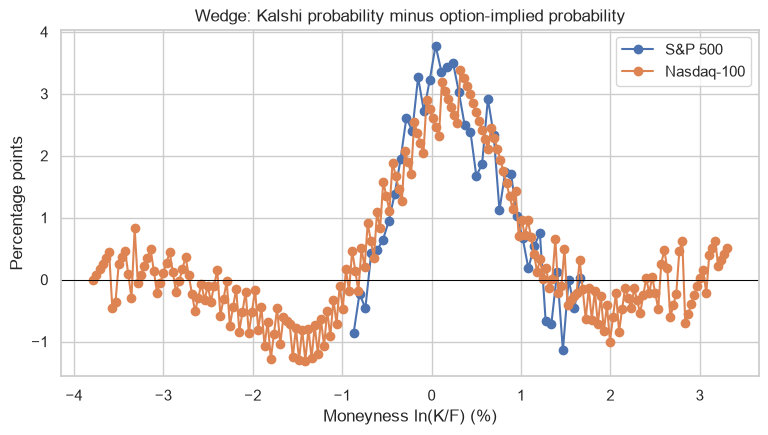

In [8]:
plt.figure(figsize=(9, 4.5))
for e, nombre in [(esc_spx, "S&P 500"), (esc_ndx, "Nasdaq-100")]:
    x = e[(e["kalshi_mid"] > 0.02) & (e["kalshi_mid"] < 0.98)]
    plt.plot(x["k"] * 100, x["wedge"] * 100, marker="o", label=nombre)
plt.axhline(0, color="black", lw=0.7)
plt.title("Wedge: Kalshi probability minus option-implied probability")
plt.xlabel("Moneyness ln(K/F) (%)")
plt.ylabel("Percentage points")
plt.legend()
plt.savefig("figures/wedge_by_moneyness.png", bbox_inches="tight")
plt.show()

## Part 6. The Kalshi smile

Inverting the digital formula N(d2), each Kalshi price becomes an implied volatility, and we can put it over the option smile.

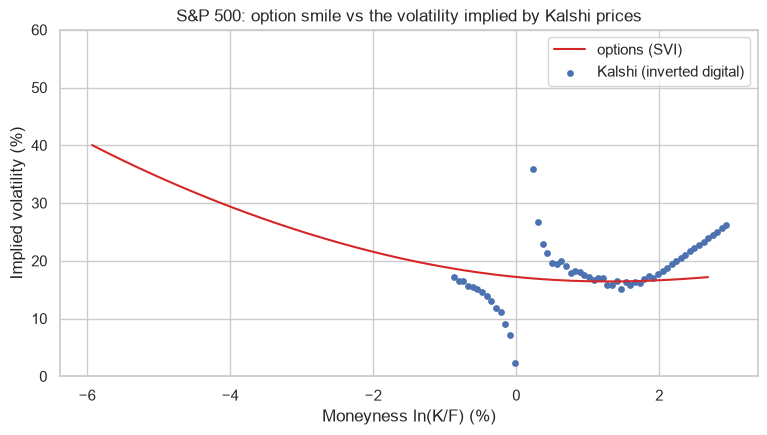

In [9]:
plt.figure(figsize=(9, 4.5))
k = np.linspace(otm_spx["k"].min(), otm_spx["k"].max(), 200)
plt.plot(k * 100, np.sqrt(svi(p_spx, k) / T_spx) * 100, color="tab:red", label="options (SVI)")
plt.scatter(esc_spx["k"] * 100, esc_spx["kalshi_implied_vol"] * 100, s=15, label="Kalshi (inverted digital)")
plt.title("S&P 500: option smile vs the volatility implied by Kalshi prices")
plt.xlabel("Moneyness ln(K/F) (%)")
plt.ylabel("Implied volatility (%)")
plt.ylim(0, 60)
plt.legend()
plt.savefig("figures/kalshi_smile.png", bbox_inches="tight")
plt.show()

A flat volatility N(d2) would misprice the digital: in a skewed smile the probability of finishing above a strike depends also on the slope of the smile (the skew correction), which the SVI + Breeden-Litzenberger approach includes. The Kalshi implied volatilities are much noisier because each one comes from a single bid-ask quote.

## Conclusions

- The two markets give almost the same distribution. For the S&P 500 the mean absolute gap between the Kalshi probability and the option-implied probability is 1.6 percentage points (maximum 3.8, the Kolmogorov-Smirnov distance), and for the Nasdaq-100 0.8 points.
- The gap is smaller than the cost of trading it: the average half spread on Kalshi is about 2 points, and the option price is inside the Kalshi bid-ask in 63% of the S&P strikes and 90% of the Nasdaq strikes. Most of the wedge cannot be arbitraged.
- The gap is not random: on the S&P 500 Kalshi is above the options around the money (up to +3.4 points at 7.675), so Kalshi traders put a little more probability on the index finishing higher than the option market.
- Limits of this snapshot: it was taken at 4:25 pm New York (after the cash close, options quotes are the last ones of the day and Kalshi quotes are live), and it is one expiry. For the thesis the same measure has to be built every day, which is the panel variable "distance between the two distributions" proposed in my GP.